In [2]:
import numpy as np
import pandas as pd

data = np.load("../dataset/fir_frames.npz", allow_pickle=True)

X = data["X"]
y = data["y"]
sessions = data["session"]
file_ids = data["file_id"]
classes = data["classes"]

print("Dataset loaded successfully!")
print("Classes:", classes)

Dataset loaded successfully!
Classes: ['walk' 'stand' 'standup' 'sit' 'sitdown' 'falling' 'falled' 'lying'
 'sleeping' 'active']


In [3]:
data = np.load("../dataset/fir_frames.npz", allow_pickle=True)

X = data["X"]
y = data["y"]
sessions = data["session"]
file_ids = data["file_id"]
classes = data["classes"]

print("Dataset loaded successfully!")
print("Classes:", classes)

Dataset loaded successfully!
Classes: ['walk' 'stand' 'standup' 'sit' 'sitdown' 'falling' 'falled' 'lying'
 'sleeping' 'active']


In [4]:
# Original class names from dataset
class_names = [str(c) for c in classes]

fall_ids = [
    class_names.index("falling"),
    class_names.index("falled")
]

print("All classes:", class_names)
print("Fall class IDs:", fall_ids)

All classes: ['walk', 'stand', 'standup', 'sit', 'sitdown', 'falling', 'falled', 'lying', 'sleeping', 'active']
Fall class IDs: [5, 6]


In [6]:
FPS_REFERENCE = 7.8

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FALLING_ID = class_names.index("falling")
FALLED_ID = class_names.index("falled")

segments = []

for fid in np.unique(file_ids):

    indices = np.where(file_ids == fid)[0]

    chunks = np.split(
        indices,
        np.where(np.diff(indices) != 1)[0] + 1
    )

    for chunk in chunks:

        if len(chunk) == 0:
            continue

        labels = y[chunk]

        changes = np.where(np.diff(labels) != 0)[0] + 1
        parts = np.split(np.arange(len(chunk)), changes)

        for part in parts:

            label = int(labels[part[0]])

            if label not in [FALLING_ID, FALLED_ID]:
                continue

            segment_indices = chunk[part]

            segments.append({
                "file_id": fid,
                "session": sessions[segment_indices[0]],
                "class": class_names[label],
                "start": int(segment_indices[0]),
                "end": int(segment_indices[-1]),
                "frames": len(segment_indices),
                "duration_sec": round(len(segment_indices) / FPS_REFERENCE, 2)
            })

segments_df = pd.DataFrame(segments)

print("Total fall segments:", len(segments_df))
display(segments_df.head(10))

Total fall segments: 628


,file_id,session,class,start,end,frames,duration_sec
0,0,20200626_01,falling,245,270,26,3.33
1,0,20200626_01,falled,271,288,18,2.31
2,0,20200626_01,falling,370,399,30,3.85
3,1,20200626_01,falling,1505,1554,50,6.41
4,1,20200626_01,falling,1682,1754,73,9.36
5,2,20200626_01,falling,2174,2452,279,35.77
6,2,20200626_01,falling,3547,3591,45,5.77
7,2,20200626_01,falled,3592,3681,90,11.54
8,3,20200626_01,falling,3982,4018,37,4.74
9,3,20200626_01,falling,4061,4080,20,2.56


In [8]:
sample_segments = segments_df.sample(
    n=10,
    random_state=42
).reset_index(drop=True)

display(sample_segments)

,file_id,session,class,start,end,frames,duration_sec
0,117,20200630_02,falled,208276,208285,10,1.28
1,118,20200630_02,falling,209415,209452,38,4.87
2,115,20200630_02,falled,204804,204828,25,3.21
3,33,20200628_01,falling,49481,49511,31,3.97
4,101,20200629_02,falled,180721,180900,180,23.08
5,33,20200628_01,falling,52031,52076,46,5.90
6,91,20200629_02,falled,161530,161801,272,34.87
7,16,20200627_01,falled,25291,25317,27,3.46
8,110,20200629_02,falled,197948,198047,100,12.82
9,26,20200628_01,falling,41557,41590,34,4.36


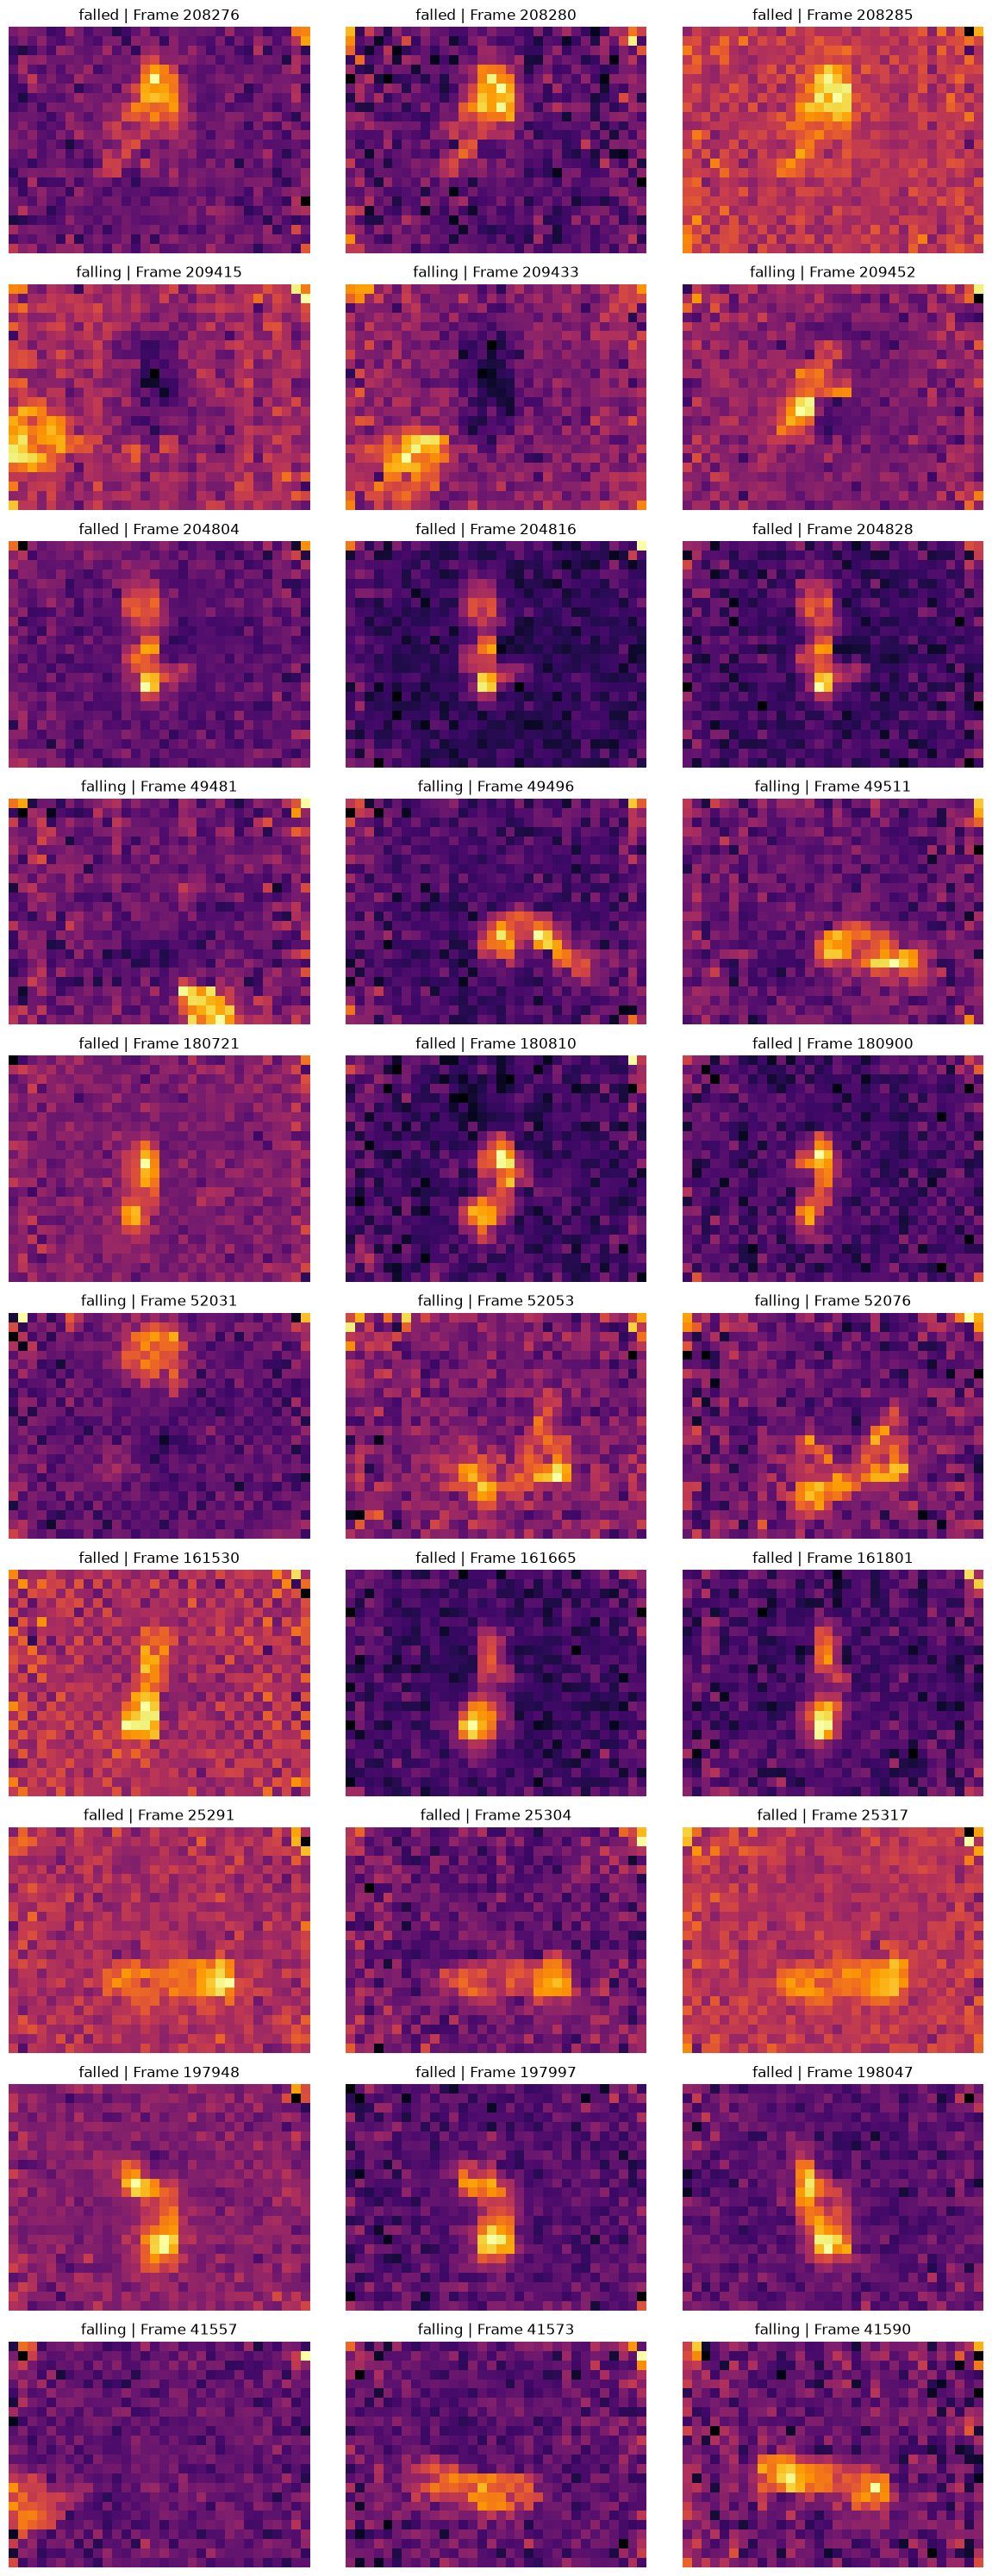

In [9]:
fig, axes = plt.subplots(10, 3, figsize=(12, 30))

for i, segment in sample_segments.iterrows():

    start = segment["start"]
    end = segment["end"]

    frame_indices = [
        start,
        (start + end) // 2,
        end
    ]

    for j, frame_idx in enumerate(frame_indices):

        axes[i, j].imshow(X[frame_idx], cmap="inferno")
        axes[i, j].set_title(
            f'{segment["class"]} | Frame {frame_idx}'
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [11]:
print("Segments per class:")
display(segments_df["class"].value_counts())

print("\nTotal segments:", len(segments_df))

Segments per class:


class
falling    406
falled     222
Name: count, dtype: int64


Total segments: 628


In [13]:
import os

VIDEO_DIR = "../FIR-Image-Action-Dataset/video"

print("Video folder exists:", os.path.exists(VIDEO_DIR))

if os.path.exists(VIDEO_DIR):
    video_files = []

    for root, dirs, files in os.walk(VIDEO_DIR):
        for file in files:
            if file.lower().endswith((".mp4", ".avi", ".mov", ".mkv")):
                video_files.append(os.path.join(root, file))

    print("Number of videos:", len(video_files))

    for video in video_files[:20]:
        print(video)
else:
    print("Video folder not found. Check VIDEO_DIR.")

Video folder exists: True
Number of videos: 126
../FIR-Image-Action-Dataset/video\20200626_154313_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_154556_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_155021_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_155441_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_155946_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_160219_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_160522_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_160716_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_161131_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_161431_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_161947_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/video\20200626_162405_mlx90640_01_light_none.mp4
../FIR-Image-Action-Dataset/

In [14]:
import os
import glob

VIDEO_DIR = "../FIR-Image-Action-Dataset/video"

video_files = sorted(
    glob.glob(os.path.join(VIDEO_DIR, "*.mp4"))
)

print("Number of videos:", len(video_files))

selected_ids = [117, 118, 115, 101, 91]

video_mapping = {}

for fid in selected_ids:

    if fid < len(video_files):
        video_mapping[fid] = video_files[fid]

        print("\nFile ID:", fid)
        print("Video:", video_files[fid])
    else:
        print("File ID not found:", fid)

Number of videos: 126

File ID: 117
Video: ../FIR-Image-Action-Dataset/video\20200630_150314_mlx90640_02_light_none.mp4

File ID: 118
Video: ../FIR-Image-Action-Dataset/video\20200630_151414_mlx90640_02_light_none.mp4

File ID: 115
Video: ../FIR-Image-Action-Dataset/video\20200630_145508_mlx90640_02_light_none.mp4

File ID: 101
Video: ../FIR-Image-Action-Dataset/video\20200629_163430_mlx90640_02_light_none.mp4

File ID: 91
Video: ../FIR-Image-Action-Dataset/video\20200629_152249_mlx90640_02_light_none.mp4


In [16]:
%pip install opencv-python

   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.0 MB 1.7 MB/s eta 0:00:29
    --------------------------------------- 1.0/48.0 MB 1.8 MB/s eta 0:00:26
   - -------------------------------------- 1.6/48.0 MB 2.0 MB/s eta 0:00:24
   - -------------------------------------- 2.1/48.0 MB 2.2 MB/s eta 0:00:22
   -- ------------------------------------- 2.9/48.0 MB 2.5 MB/s eta 0:00:19
   --- ------------------------------------ 3.7/48.0 MB 2.7 MB/s eta 0:00:17
   --- ------------------------------------ 4.5/48.0 MB 2.9 MB/s eta 0:00:16
   ---- ----------------------------------- 5.5/48.0 MB 3.1 MB/s eta 0:00:14
   ----- ---------------------------------- 6.3/48.0 MB 3.2 MB/s eta 0:00:14
   ------ --------------------------------- 7.3/48.0 MB 3.3 MB/s eta 0:00:13
   ------ --------------------------------- 8.1/48.0 MB 3.4 MB/s eta 0:00:12
   ------- --

In [17]:
import cv2

for fid, video_path in video_mapping.items():

    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = total_frames / fps if fps > 0 else 0

    print("\nFile ID:", fid)
    print("Video:", os.path.basename(video_path))
    print("FPS:", fps)
    print("Total frames:", total_frames)
    print("Duration:", round(duration, 2), "seconds")

    cap.release()


File ID: 117
Video: 20200630_150314_mlx90640_02_light_none.mp4
FPS: 25.0
Total frames: 4802
Duration: 192.08 seconds

File ID: 118
Video: 20200630_151414_mlx90640_02_light_none.mp4
FPS: 25.0
Total frames: 7082
Duration: 283.28 seconds

File ID: 115
Video: 20200630_145508_mlx90640_02_light_none.mp4
FPS: 25.0
Total frames: 5272
Duration: 210.88 seconds

File ID: 101
Video: 20200629_163430_mlx90640_02_light_none.mp4
FPS: 25.0
Total frames: 4699
Duration: 187.96 seconds

File ID: 91
Video: 20200629_152249_mlx90640_02_light_none.mp4
FPS: 25.0
Total frames: 8147
Duration: 325.88 seconds


In [18]:
import os
import glob
import cv2
import numpy as np
import pandas as pd

VIDEO_DIR = "../FIR-Image-Action-Dataset/video"

video_files = sorted(
    glob.glob(os.path.join(VIDEO_DIR, "*.mp4"))
)

mapping_results = []

for fid in np.unique(file_ids):

    indices = np.where(file_ids == fid)[0]

    thermal_frames = len(indices)
    thermal_duration = thermal_frames / FPS_REFERENCE

    video_path = video_files[int(fid)]

    cap = cv2.VideoCapture(video_path)

    video_fps = cap.get(cv2.CAP_PROP_FPS)
    video_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    video_duration = (
        video_total / video_fps
        if video_fps > 0 else 0
    )

    cap.release()

    difference = abs(
        thermal_duration - video_duration
    )

    mapping_results.append({
        "file_id": int(fid),
        "video": os.path.basename(video_path),
        "thermal_frames": thermal_frames,
        "thermal_duration": round(thermal_duration, 2),
        "video_duration": round(video_duration, 2),
        "difference_sec": round(difference, 2)
    })

mapping_df = pd.DataFrame(mapping_results)

display(mapping_df.head(15))

print("Total files:", len(mapping_df))
print(
    "Mean duration difference:",
    round(mapping_df["difference_sec"].mean(), 2),
    "seconds"
)

print(
    "Maximum difference:",
    round(mapping_df["difference_sec"].max(), 2),
    "seconds"
)

,file_id,video,thermal_frames,thermal_duration,video_duration,difference_sec
0,0,20200626_154313_mlx90640_01_light_none.mp4,563,72.18,75.68,3.50
1,1,20200626_154556_mlx90640_01_light_none.mp4,1348,172.82,172.64,0.18
2,2,20200626_155021_mlx90640_01_light_none.mp4,1859,238.33,238.64,0.31
3,3,20200626_155441_mlx90640_01_light_none.mp4,2042,261.79,262.08,0.29
4,4,20200626_155946_mlx90640_01_light_none.mp4,1013,129.87,133.72,3.85
5,5,20200626_160219_mlx90640_01_light_none.mp4,1252,160.51,162.32,1.81
6,6,20200626_160522_mlx90640_01_light_none.mp4,743,95.26,95.24,0.02
7,7,20200626_160716_mlx90640_01_light_none.mp4,1514,194.10,194.32,0.22
8,8,20200626_161131_mlx90640_01_light_none.mp4,1213,155.51,155.48,0.03
9,9,20200626_161431_mlx90640_01_light_none.mp4,1675,214.74,215.16,0.42


Total files: 126
Mean duration difference: 2.12 seconds
Maximum difference: 15.77 seconds


In [19]:
print("Number of mapped files:", len(mapping_df))

print("\nDifference statistics:")
display(mapping_df["difference_sec"].describe())

print("\nFiles with difference greater than 2 seconds:")
display(
    mapping_df[
        mapping_df["difference_sec"] > 2
    ].sort_values("difference_sec", ascending=False)
)

print("\nFiles with difference greater than 5 seconds:")
display(
    mapping_df[
        mapping_df["difference_sec"] > 5
    ].sort_values("difference_sec", ascending=False)
)

Number of mapped files: 126

Difference statistics:


count    126.000000
mean       2.120000
std        2.324948
min        0.010000
25%        0.295000
50%        1.860000
75%        3.507500
max       15.770000
Name: difference_sec, dtype: float64


Files with difference greater than 2 seconds:


,file_id,video,thermal_frames,thermal_duration,video_duration,difference_sec
100,100,20200629_163028_mlx90640_02_light_none.mp4,1525,195.51,211.28,15.77
87,87,20200629_145306_mlx90640_02_light_none.mp4,2167,277.82,288.56,10.74
109,109,20200629_171745_mlx90640_02_light_none.mp4,1733,222.18,229.20,7.02
105,105,20200629_165419_mlx90640_02_light_none.mp4,1904,244.10,250.36,6.26
70,70,20200629_120225_mlx90640_02_light_none.mp4,1748,224.10,230.04,5.94
95,95,20200629_154713_mlx90640_02_light_none.mp4,2208,283.08,288.80,5.72
120,120,20200630_152710_mlx90640_02_light_none.mp4,3233,414.49,420.20,5.71
125,125,20200630_161552_mlx90640_02_light_none.mp4,2542,325.90,331.60,5.70
86,86,20200629_144306_mlx90640_02_light_none.mp4,2264,290.26,295.68,5.42
35,35,20200628_151442_mlx90640_01_light_none.mp4,1543,197.82,203.24,5.42



Files with difference greater than 5 seconds:


,file_id,video,thermal_frames,thermal_duration,video_duration,difference_sec
100,100,20200629_163028_mlx90640_02_light_none.mp4,1525,195.51,211.28,15.77
87,87,20200629_145306_mlx90640_02_light_none.mp4,2167,277.82,288.56,10.74
109,109,20200629_171745_mlx90640_02_light_none.mp4,1733,222.18,229.20,7.02
105,105,20200629_165419_mlx90640_02_light_none.mp4,1904,244.10,250.36,6.26
70,70,20200629_120225_mlx90640_02_light_none.mp4,1748,224.10,230.04,5.94
95,95,20200629_154713_mlx90640_02_light_none.mp4,2208,283.08,288.80,5.72
120,120,20200630_152710_mlx90640_02_light_none.mp4,3233,414.49,420.20,5.71
125,125,20200630_161552_mlx90640_02_light_none.mp4,2542,325.90,331.60,5.70
86,86,20200629_144306_mlx90640_02_light_none.mp4,2264,290.26,295.68,5.42
35,35,20200628_151442_mlx90640_01_light_none.mp4,1543,197.82,203.24,5.42


In [20]:
selected_ids = [117, 118, 115, 101, 91]

display(
    mapping_df[
        mapping_df["file_id"].isin(selected_ids)
    ].sort_values("file_id")
)

,file_id,video,thermal_frames,thermal_duration,video_duration,difference_sec
91,91,20200629_152249_mlx90640_02_light_none.mp4,2528,324.10,325.88,1.78
101,101,20200629_163430_mlx90640_02_light_none.mp4,1425,182.69,187.96,5.27
115,115,20200630_145508_mlx90640_02_light_none.mp4,1631,209.10,210.88,1.78
117,117,20200630_150314_mlx90640_02_light_none.mp4,1497,191.92,192.08,0.16
118,118,20200630_151414_mlx90640_02_light_none.mp4,2177,279.10,283.28,4.18


In [21]:
print("Dataset files:", len(np.unique(file_ids)))
print("Video files:", len(video_files))

print("\nFirst 20 video filenames:")
for i in range(20):
    print(i, os.path.basename(video_files[i]))

Dataset files: 126
Video files: 126

First 20 video filenames:
0 20200626_154313_mlx90640_01_light_none.mp4
1 20200626_154556_mlx90640_01_light_none.mp4
2 20200626_155021_mlx90640_01_light_none.mp4
3 20200626_155441_mlx90640_01_light_none.mp4
4 20200626_155946_mlx90640_01_light_none.mp4
5 20200626_160219_mlx90640_01_light_none.mp4
6 20200626_160522_mlx90640_01_light_none.mp4
7 20200626_160716_mlx90640_01_light_none.mp4
8 20200626_161131_mlx90640_01_light_none.mp4
9 20200626_161431_mlx90640_01_light_none.mp4
10 20200626_161947_mlx90640_01_light_none.mp4
11 20200626_162405_mlx90640_01_light_none.mp4
12 20200626_162728_mlx90640_01_light_none.mp4
13 20200626_163311_mlx90640_01_light_none.mp4
14 20200626_165412_mlx90640_01_light_none.mp4
15 20200626_175151_mlx90640_01_light_none.mp4
16 20200627_184507_mlx90640_01_light_none.mp4
17 20200627_185209_mlx90640_01_light_none.mp4
18 20200627_185542_mlx90640_01_light_none.mp4
19 20200627_190147_mlx90640_01_light_none.mp4


In [22]:
import os
import pandas as pd
import numpy as np

check_rows = []

for fid in range(126):
    indices = np.where(file_ids == fid)[0]

    session_values = np.unique(sessions[indices])
    video_name = os.path.basename(video_files[fid])

    session_name = str(session_values[0])

    video_date = video_name[:8]
    session_date = session_name[:8]

    check_rows.append({
        "file_id": fid,
        "session": session_name,
        "video": video_name,
        "same_date": video_date == session_date,
        "one_session": len(session_values) == 1
    })

check_df = pd.DataFrame(check_rows)

print("Same date:", check_df["same_date"].sum(), "/ 126")
print("One session per file:", check_df["one_session"].sum(), "/ 126")

print("\nMismatches:")
display(check_df[
    (check_df["same_date"] == False) |
    (check_df["one_session"] == False)
])

Same date: 126 / 126
One session per file: 126 / 126

Mismatches:


,file_id,session,video,same_date,one_session


In [23]:
fid = 117

print("VIDEO:")
print(os.path.basename(video_files[fid]))

print("\nFALL SEGMENTS:")

display(
    segments_df[segments_df["file_id"] == fid][
        ["class", "start", "end", "frames", "duration_sec"]
    ].reset_index(drop=True)
)

VIDEO:
20200630_150314_mlx90640_02_light_none.mp4

FALL SEGMENTS:


,class,start,end,frames,duration_sec
0,falling,207946,207968,23,2.95
1,falled,207969,207985,17,2.18
2,falling,208074,208105,32,4.10
3,falling,208169,208195,27,3.46
4,falled,208196,208202,7,0.90
5,falling,208254,208275,22,2.82
6,falled,208276,208285,10,1.28
7,falling,208390,208427,38,4.87
8,falling,208572,208596,25,3.21
9,falled,208597,208608,12,1.54


Segment: 207946 to 207968
Class: falling
Local thermal frames: 106 to 128


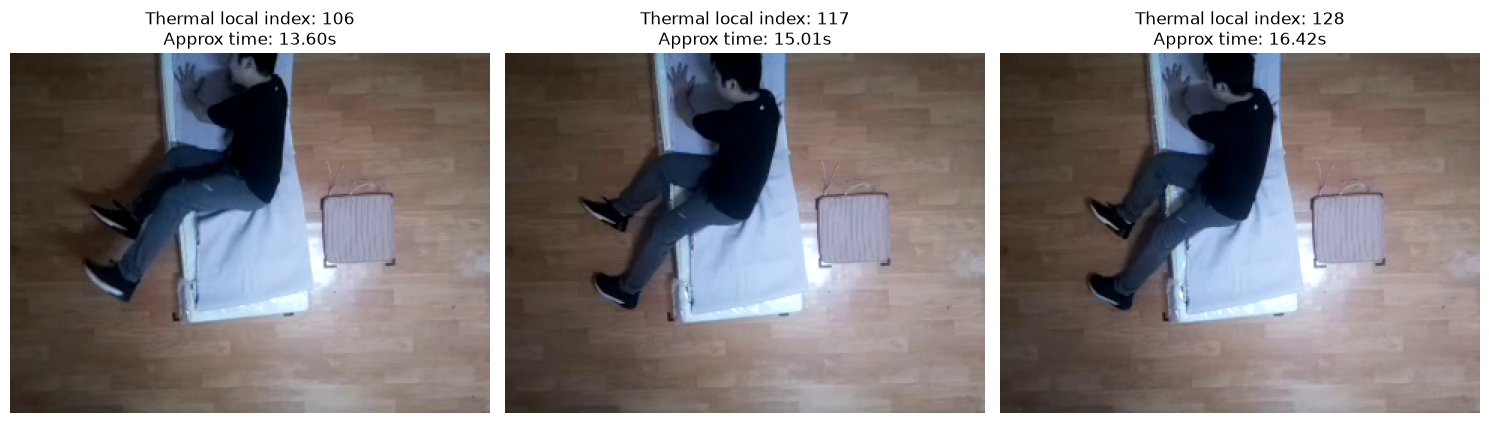

In [24]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os

fid = 117

# First falling segment
segment = segments_df[
    (segments_df["file_id"] == fid) &
    (segments_df["class"] == "falling")
].iloc[0]

start = int(segment["start"])
end = int(segment["end"])

# Thermal indices belonging to this file
file_indices = np.where(file_ids == fid)[0]

local_start = np.where(file_indices == start)[0][0]
local_end = np.where(file_indices == end)[0][0]

# Approximate relative timestamps
thermal_total = len(file_indices)

relative_positions = [
    local_start,
    (local_start + local_end) // 2,
    local_end
]

video_path = video_files[fid]

cap = cv2.VideoCapture(video_path)

video_fps = cap.get(cv2.CAP_PROP_FPS)
video_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

frames_rgb = []

for pos in relative_positions:

    approximate_time = pos / thermal_total * (video_total / video_fps)
    video_frame_number = int(approximate_time * video_fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, video_frame_number)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames_rgb.append((frame, pos, approximate_time))

cap.release()

print("Segment:", start, "to", end)
print("Class:", segment["class"])
print("Local thermal frames:", local_start, "to", local_end)

fig, axes = plt.subplots(1, len(frames_rgb), figsize=(15, 5))

for ax, (frame, pos, t) in zip(axes, frames_rgb):
    ax.imshow(frame)
    ax.set_title(f"Thermal local index: {pos}\nApprox time: {t:.2f}s")
    ax.axis("off")

plt.tight_layout()
plt.show()

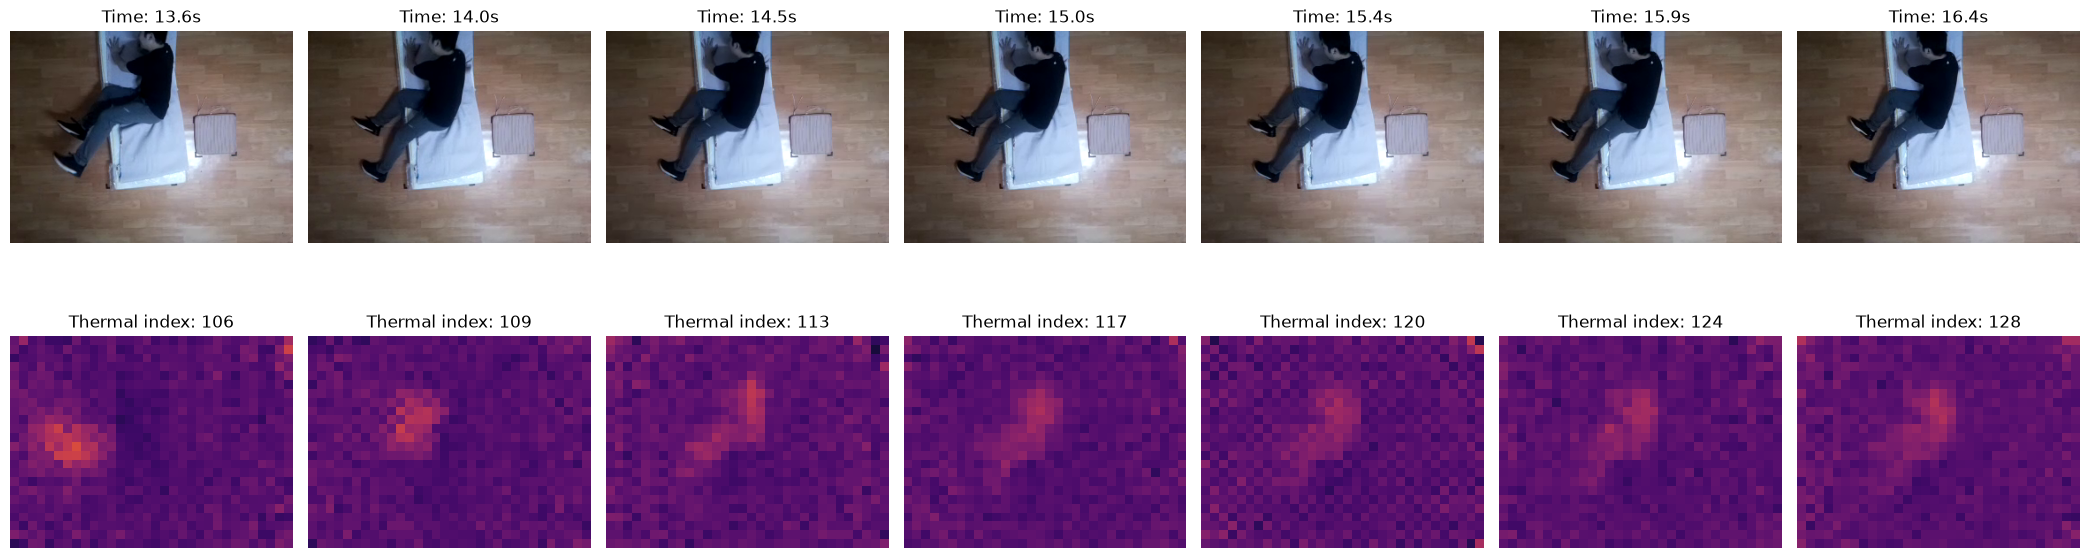

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

fid = 117

segment = segments_df[
    (segments_df["file_id"] == fid) &
    (segments_df["class"] == "falling")
].iloc[0]

start = int(segment["start"])
end = int(segment["end"])

file_indices = np.where(file_ids == fid)[0]

local_start = np.where(file_indices == start)[0][0]
local_end = np.where(file_indices == end)[0][0]

positions = np.linspace(
    local_start, local_end, 7
).astype(int)

video_path = video_files[fid]
cap = cv2.VideoCapture(video_path)

video_fps = cap.get(cv2.CAP_PROP_FPS)
video_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
thermal_total = len(file_indices)

fig, axes = plt.subplots(2, 7, figsize=(21, 7))

for i, pos in enumerate(positions):

    # Approximate video position
    approximate_time = (
        pos / thermal_total
    ) * (video_total / video_fps)

    video_frame_number = int(approximate_time * video_fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, video_frame_number)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[0, i].imshow(frame)

    # Corresponding thermal frame
    global_index = file_indices[pos]
    thermal_frame = X[global_index].astype(np.float32)

    axes[1, i].imshow(
        np.clip(thermal_frame, -3, 10),
        cmap="inferno",
        vmin=-3,
        vmax=10
    )

    axes[0, i].set_title(f"Time: {approximate_time:.1f}s")
    axes[1, i].set_title(f"Thermal index: {pos}")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

cap.release()
plt.tight_layout()
plt.show()

IndexError: index 8 is out of bounds for axis 1 with size 8

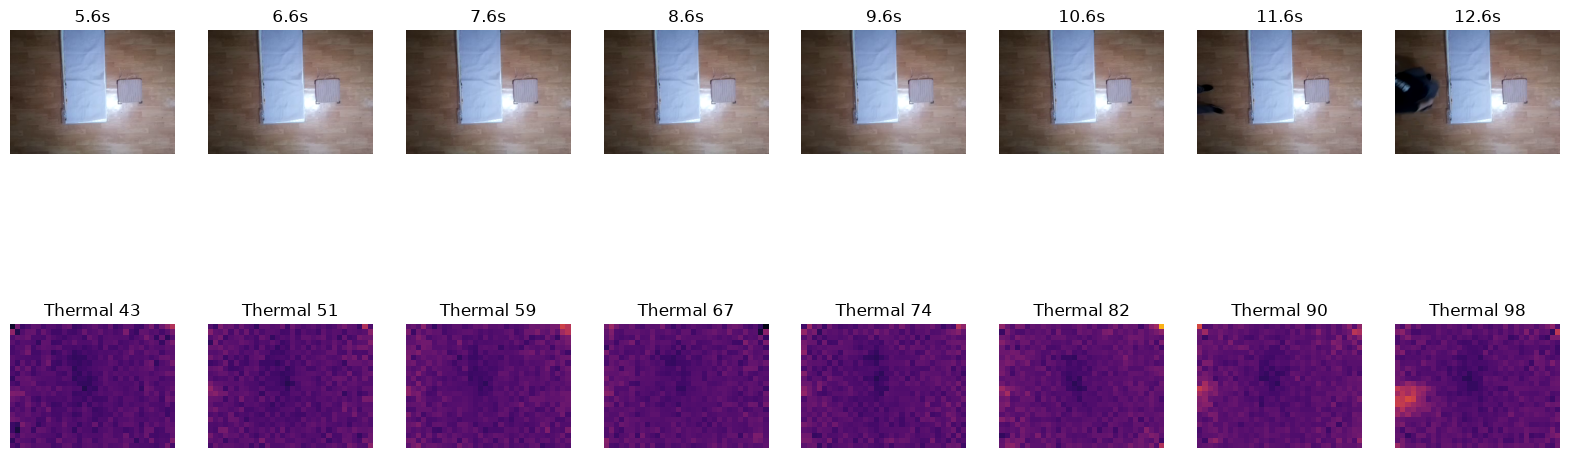

In [26]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

fid = 117
video_path = video_files[fid]

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

# Approximate event time
event_start = 13.6

# Inspect 8 seconds before and after
times = np.arange(event_start - 8, event_start + 8.1, 1)

fig, axes = plt.subplots(2, 8, figsize=(20, 7))

for i, t in enumerate(times):

    frame_number = int(t * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[0, i].imshow(frame)

    axes[0, i].set_title(f"{t:.1f}s")
    axes[0, i].axis("off")

    # Approximate corresponding thermal index
    thermal_pos = int(t / (cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps)
                      * len(file_indices))

    thermal_pos = np.clip(thermal_pos, 0, len(file_indices)-1)

    thermal_frame = X[file_indices[thermal_pos]].astype(np.float32)

    axes[1, i].imshow(
        np.clip(thermal_frame, -3, 10),
        cmap="inferno",
        vmin=-3,
        vmax=10
    )

    axes[1, i].set_title(f"Thermal {thermal_pos}")
    axes[1, i].axis("off")

cap.release()
plt.tight_layout()
plt.show()

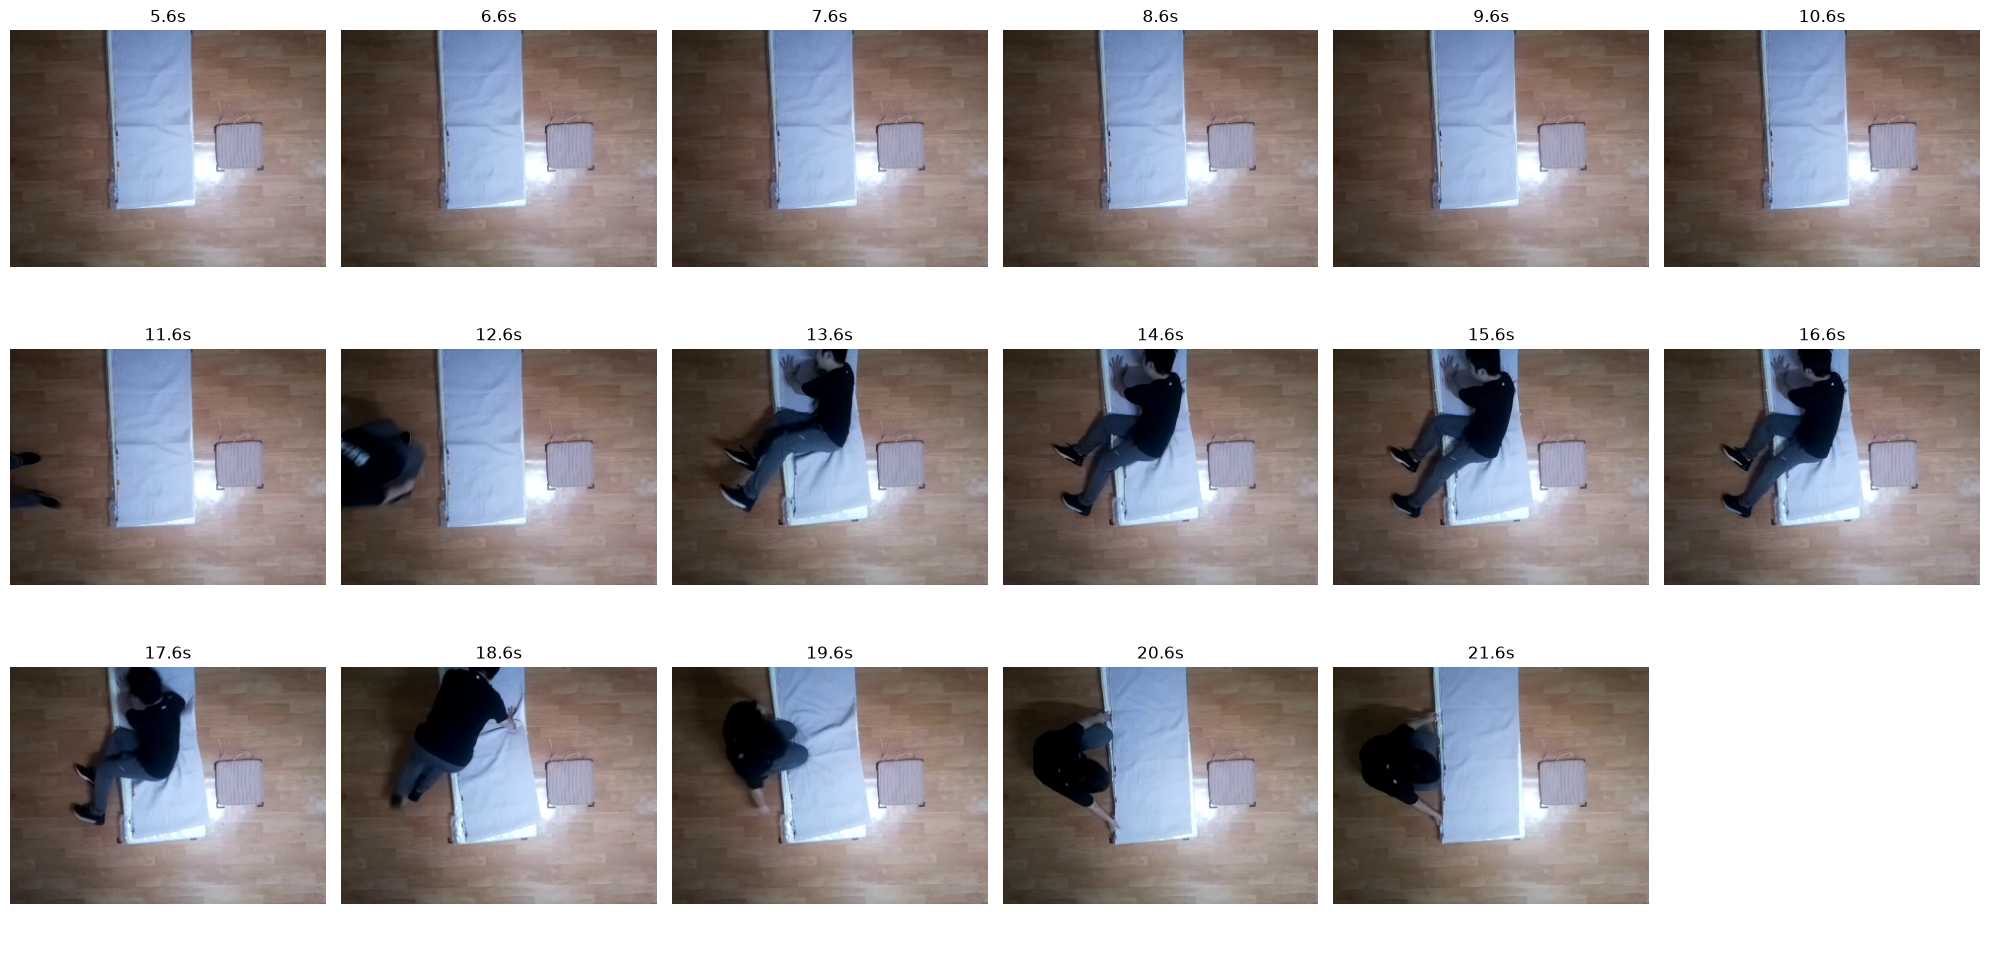

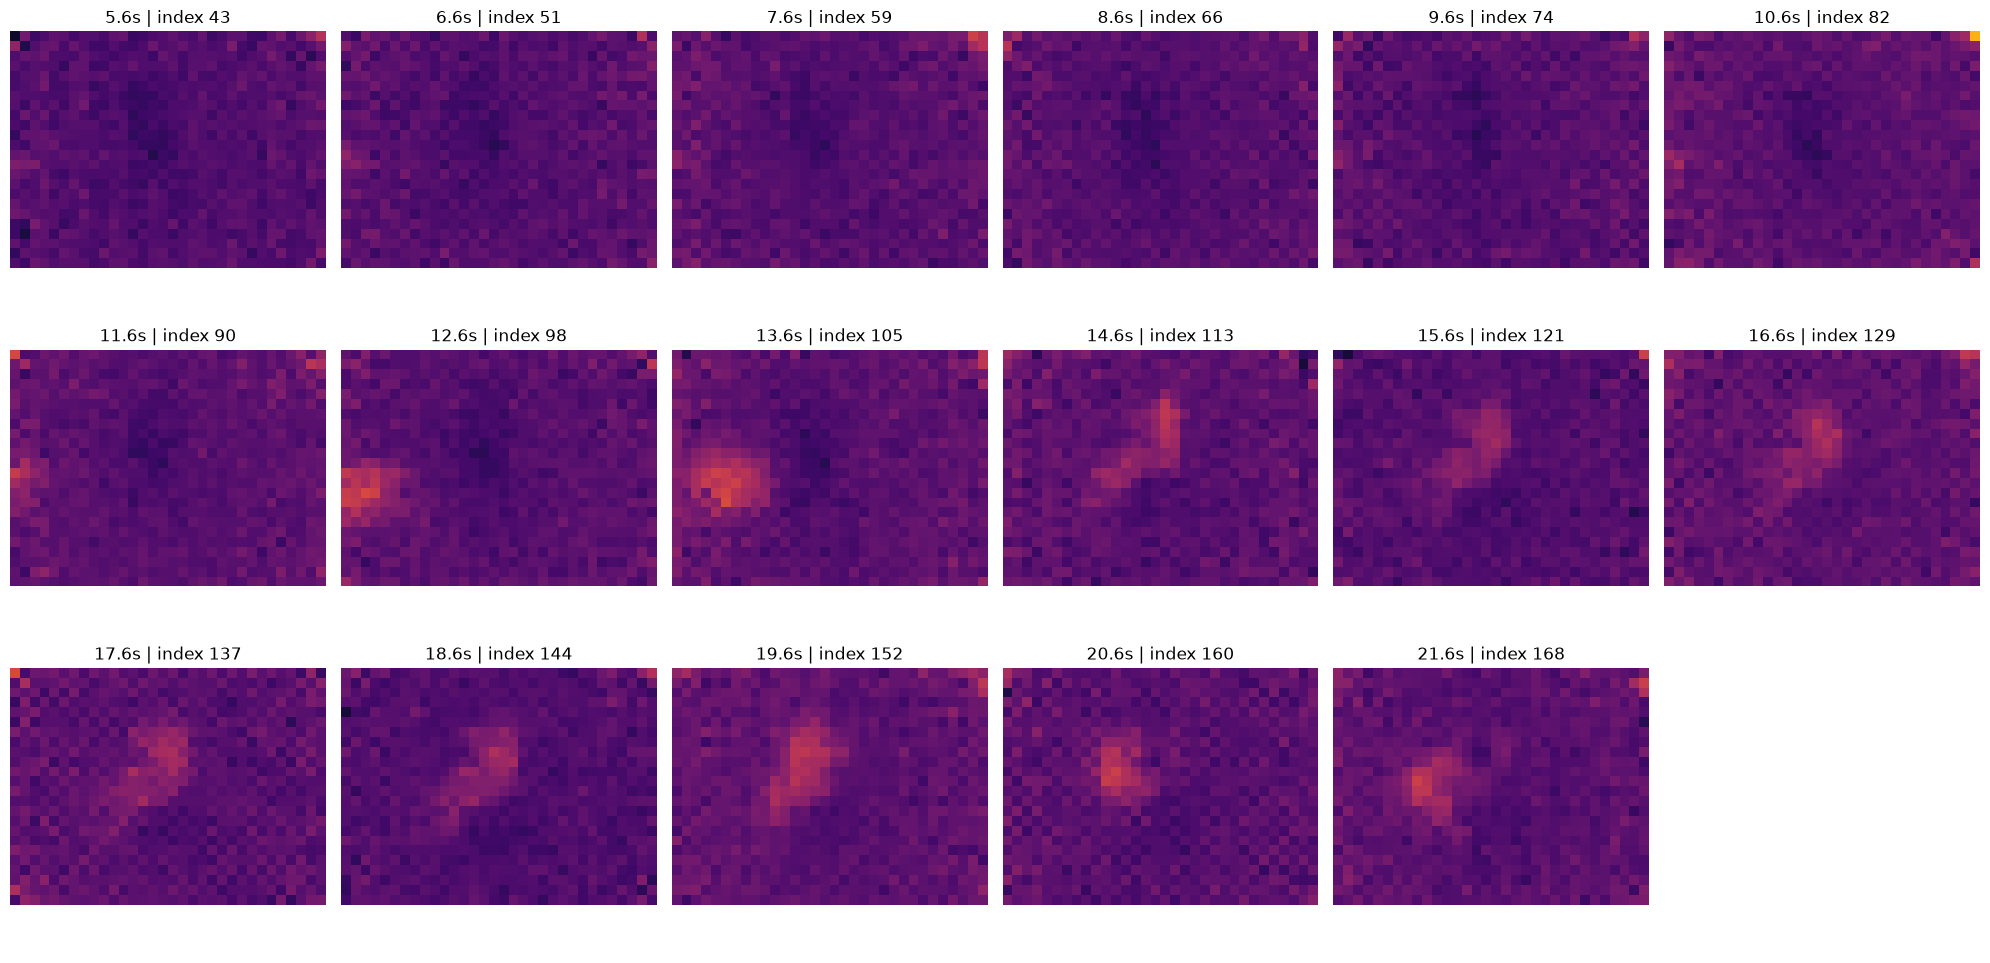

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

fid = 117
video_path = video_files[fid]

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
video_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_duration = video_total / fps

file_indices = np.where(file_ids == fid)[0]
thermal_total = len(file_indices)

times = np.arange(5.6, 22.0, 1.0)

fig, axes = plt.subplots(3, 6, figsize=(20, 10))
axes = axes.flatten()

for i, t in enumerate(times):

    frame_number = int(t * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        axes[i].imshow(frame)

    axes[i].set_title(f"{t:.1f}s")
    axes[i].axis("off")

for i in range(len(times), len(axes)):
    axes[i].axis("off")

cap.release()

plt.tight_layout()
plt.show()

# Thermal frames
fig, axes = plt.subplots(3, 6, figsize=(20, 10))
axes = axes.flatten()

for i, t in enumerate(times):

    thermal_pos = int(
        (t / video_duration) * (thermal_total - 1)
    )

    thermal_pos = np.clip(
        thermal_pos, 0, thermal_total - 1
    )

    global_index = file_indices[thermal_pos]

    thermal_frame = X[global_index].astype(np.float32)

    axes[i].imshow(
        np.clip(thermal_frame, -3, 10),
        cmap="inferno",
        vmin=-3,
        vmax=10
    )

    axes[i].set_title(f"{t:.1f}s | index {thermal_pos}")
    axes[i].axis("off")

for i in range(len(times), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

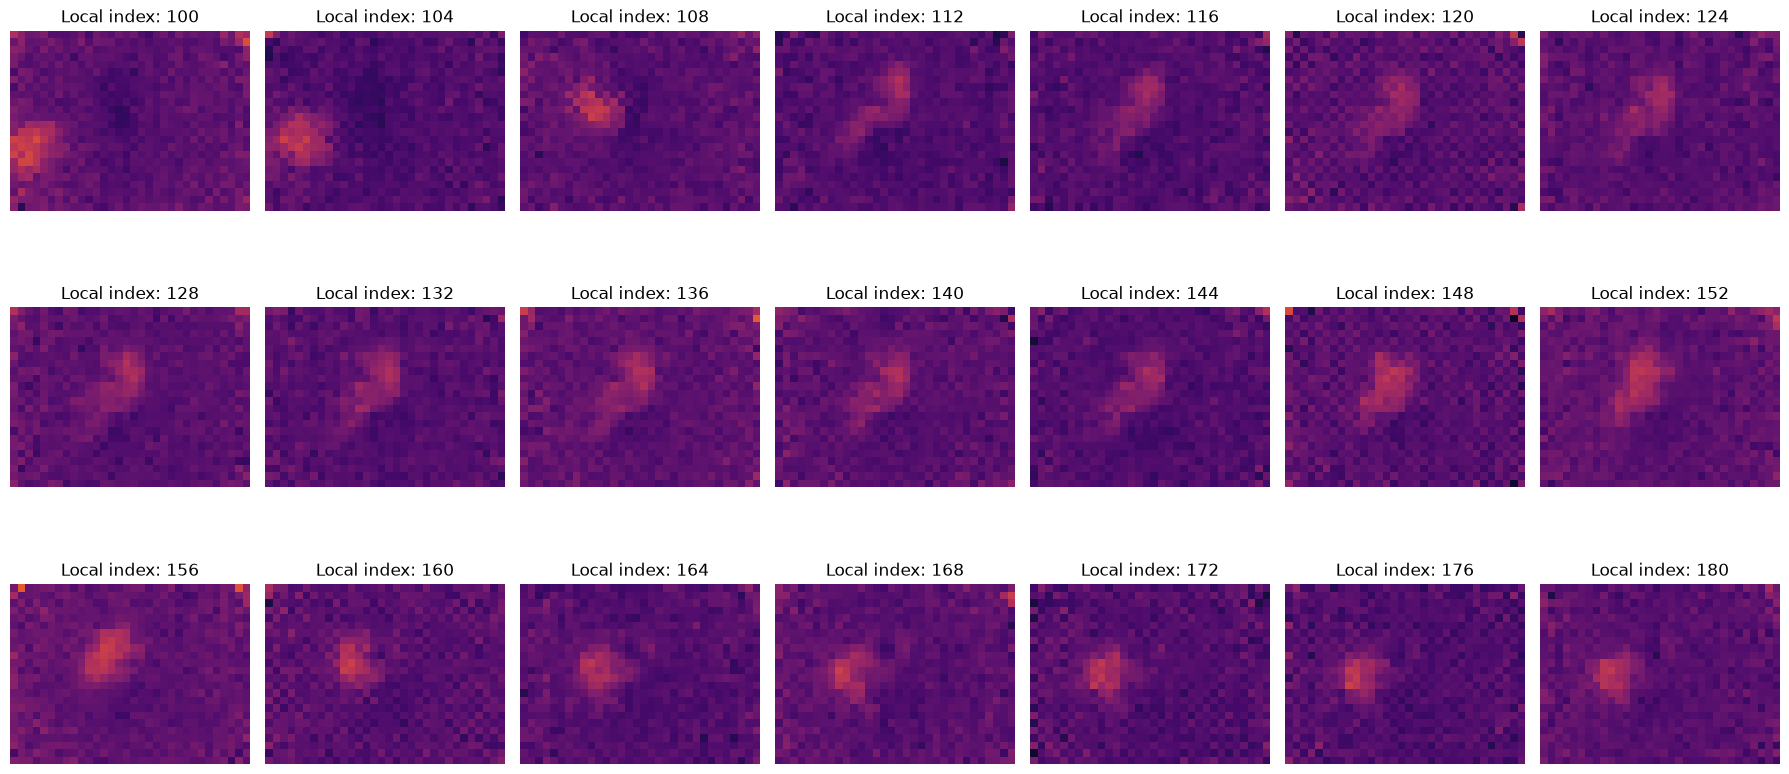

In [28]:
fid = 117

file_indices = np.where(file_ids == fid)[0]

positions = np.arange(100, 181, 4)

fig, axes = plt.subplots(3, 7, figsize=(18, 9))
axes = axes.flatten()

for i, pos in enumerate(positions):

    thermal_frame = X[file_indices[pos]].astype(np.float32)

    axes[i].imshow(
        np.clip(thermal_frame, -3, 10),
        cmap="inferno",
        vmin=-3,
        vmax=10
    )

    axes[i].set_title(f"Local index: {pos}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()